# Анализ и прогнозирование фактического конечного потребления домашних хозяйств

**Итоговый проект по дисциплине «Временные ряды»**

Исследование охватывает 2000–2023 годы. Цель — сгруппировать субъекты РФ по сходству динамики, выбрать представителей разных групп, сравнить модели Holt, ARIMA и наивный бейзлайн, проверить устойчивость прогнозов и сформулировать региональные рекомендации.

> Показатель выражен в **текущих рыночных ценах**. Его рост отражает как изменение потребления, так и инфляцию, поэтому выводы относятся к номинальной стоимости, а не напрямую к реальному уровню жизни.

## Настройка окружения

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import time_series_project as tsp

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
tsp.configure_plots()
print("Окружение настроено. Пути к данным и результатам определяются автоматически.")

Окружение настроено. Пути к данным и результатам определяются автоматически.


Все функции вынесены в `src/time_series_project.py`: это позволяет запускать один и тот же расчёт из Notebook и из командной строки без расхождения результатов.

## Этап 1. Загрузка и подготовка данных

Сначала файл читается как текст: символ `…` и десятичные запятые мешают автоматическому определению числовых типов. Затем годовые столбцы преобразуются в числа, специальные обозначения становятся пропусками. Удаляются только агрегаты и территории с неполной историей; длинные пропуски не интерполируются.

In [2]:
source = pd.read_csv(tsp.DATA_PATH, encoding="utf-8-sig", dtype=str)
print("Исходная форма:", source.shape)
print("Исходные типы данных:", source.dtypes.value_counts().to_dict())
print("Годовые столбцы:", [c for c in source.columns if str(c).isdigit()][0], "—", [c for c in source.columns if str(c).isdigit()][-1])
display(source.head(3))

raw, subjects, complete, long, excluded = tsp.load_and_prepare_data()
print("После удаления пустого технического столбца:", raw.shape)
print("Типы после преобразования:", raw.dtypes.value_counts().to_dict())
display(raw.head(2))

Исходная форма: (96, 29)
Исходные типы данных: {dtype('O'): 29}
Годовые столбцы: 2000 — 2023


,region_name,region_code,indicator_name,measure_unit,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,Unnamed: 28
0,Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего,NaN,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,"24964,9","33073,8","42325,5",50809,"63177,6","79943,6",99969,"124846,2",156161,"164847,7",183266,214113,"239135,9","262359,5","279922,2","296330,1","335157,9","352032,4","378631,5","396539,7","409455,2","482117,7","537330,3","605276,8",NaN
1,Центральный федеральный округ,30,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,"37398,9","48743,1","60043,2","71997,2","86784,2","106512,6","129801,3","159400,6","196202,6","207213,9","231720,5",272574,"302078,7","326737,5","357669,5","371888,6","428461,6","449367,4","483617,8","504322,7","522640,3","622652,4","670468,1","745978,7",NaN
2,Белгородская область,14000000000,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,"19420,9","22799,1","26386,5",31254,"39422,8","48000,4","64017,4","83720,9","110581,7","121935,4","138080,2","162871,1","187390,1","212122,3","234785,7","252179,1",299984,"321377,9","343531,1",362467,386681,"432635,6",488454,514718,NaN


После удаления пустого технического столбца: (96, 28)
Типы после преобразования: {dtype('float64'): 24, dtype('O'): 4}


,region_name,region_code,indicator_name,measure_unit,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего,NaN,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,24964.9,33073.8,42325.5,50809.0,63177.6,79943.6,99969.0,124846.2,156161.0,164847.7,183266.0,214113.0,239135.9,262359.5,279922.2,296330.1,335157.9,352032.4,378631.5,396539.7,409455.2,482117.7,537330.3,605276.8
1,Центральный федеральный округ,30,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,37398.9,48743.1,60043.2,71997.2,86784.2,106512.6,129801.3,159400.6,196202.6,207213.9,231720.5,272574.0,302078.7,326737.5,357669.5,371888.6,428461.6,449367.4,483617.8,504322.7,522640.3,622652.4,670468.1,745978.7


In [3]:
print(f"Субъектов до фильтра пропусков: {len(subjects)}")
print(f"Субъектов с полным рядом: {len(complete)}")
print(f"Строк в длинном формате: {len(long)} (= {len(complete)} регионов × 24 года)")
print(f"Пропусков в итоговом длинном наборе: {long['consumption'].isna().sum()}")
display(excluded)
display(long.head(8))

Субъектов до фильтра пропусков: 85
Субъектов с полным рядом: 79
Строк в длинном формате: 1896 (= 79 регионов × 24 года)
Пропусков в итоговом длинном наборе: 0


,region_name,missing_years,reason
0,Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего,0,Агрегат по Российской Федерации
1,Центральный федеральный округ,0,Федеральный округ
2,Северо-Западный федеральный округ,0,Федеральный округ
3,Архангельская область без автономного округа,11,Дублирующая агрегированная запись
4,Южный федеральный округ,0,Федеральный округ
5,Северо-Кавказский федеральный округ,0,Федеральный округ
6,Приволжский федеральный округ,0,Федеральный округ
7,Уральский федеральный округ,0,Федеральный округ
8,Тюменская область без автономных округов,11,Дублирующая агрегированная запись
9,Сибирский федеральный округ,0,Федеральный округ


,region_name,region_code,indicator_name,measure_unit,year,consumption
0,Алтайский край,1000000000,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,2000,15751.1
1,Алтайский край,1000000000,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,2001,21539.7
2,Алтайский край,1000000000,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,2002,28855.5
3,Алтайский край,1000000000,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,2003,35772.7
4,Алтайский край,1000000000,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,2004,44268.9
5,Алтайский край,1000000000,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,2005,54776.4
6,Алтайский край,1000000000,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,2006,70451.6
7,Алтайский край,1000000000,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,2007,86759.3


Всего исключено 17 записей: общероссийский итог, восемь федеральных округов, две дублирующие записи «без автономных округов» и шесть субъектов с пропусками. В рабочем наборе остаётся **79 регионов**, каждый представлен отдельным рядом с годовым индексом. Также исправлена техническая опечатка источника: латинская буква в названии «Калининградская область».

## Этап 2. Кластерный анализ регионов

Для каждого ряда рассчитываются шесть признаков: средний уровень, коэффициент вариации, CAGR, суммарный прирост, максимальное годовое падение и доля лет снижения. Относительные признаки нужны, чтобы алгоритм учитывал не только масштаб номинального потребления, но и характер траектории.

K-means выбран из-за интерпретируемости центроидов и удобства сравнения решений. Признаки стандартизированы, поэтому переменные с разными единицами измерения вносят сопоставимый вклад. Для воспроизводимости заданы `random_state=42` и `n_init=50`.

In [4]:
features = tsp.extract_features(complete)
clustered, evaluation, profiles, scaler, scaled = tsp.cluster_regions(features)
print("Признаки (фрагмент):")
display(features.head().round(4))
print("Сравнение числа кластеров:")
display(evaluation.round(4))

Признаки (фрагмент):


,mean_value,std_value,coefficient_of_variation,cagr,total_growth,max_annual_decline,negative_years_share
region_name,,,,,,,
Белгородская область,204367.3417,157363.9390,0.7700,0.1531,25.5033,0.0538,0.0000
Брянская область,192025.8542,146893.7277,0.7650,0.1693,35.5148,0.0168,0.0000
Владимирская область,175166.5083,135065.5409,0.7711,0.1675,34.2488,0.0359,0.0000
Воронежская область,213262.2167,158664.4216,0.7440,0.1593,28.9866,-0.0119,0.0435
Ивановская область,171060.6625,136432.6265,0.7976,0.1728,38.0681,0.0397,0.0000


Сравнение числа кластеров:


,n_clusters,silhouette_score,inertia,min_cluster_size
0,2,0.3213,332.7398,27
1,3,0.3112,271.5416,1
2,4,0.3354,218.3140,1


Для четырёх кластеров silhouette score равен **0,3354** — это максимум среди K = 2, 3, 4. Решение также содержательно разделяет устойчиво растущие ряды, ряды с периодическими снижениями и аномальную траекторию Красноярского края. Однорегиональный кластер не объединён с остальными: максимальное падение на 53,3% в 2005 году после скачка 2004 года делает его принципиально иным.

,mean_value,coefficient_of_variation,cagr,total_growth,max_annual_decline,negative_years_share,n_regions
cluster,,,,,,,
0,240358.7333,0.6609,0.1419,20.4755,0.0001,0.0114,19
1,198202.1092,0.7411,0.1601,29.6567,0.0308,0.0000,45
2,205255.2560,0.7015,0.1601,29.9612,-0.0183,0.0466,14
3,232202.5292,0.6319,0.1381,18.5816,-0.5329,0.0435,1



Кластер 0 (19 регионов):
Астраханская область, Вологодская область, Иркутская область, Камчатский край, Карачаево-Черкесская Республика, Кемеровская область, Мурманская область, Новгородская область, Новосибирская область, Пермский край, Республика Башкортостан, Республика Коми, Республика Саха (Якутия), Самарская область, Смоленская область, Томская область, Тюменская область, Хабаровский край, г. Москва

Кластер 1 (45 регионов):
Амурская область, Архангельская область, Белгородская область, Брянская область, Владимирская область, Волгоградская область, Еврейская автономная область, Ивановская область, Кабардино-Балкарская Республика, Калининградская область, Калужская область, Кировская область, Костромская область, Краснодарский край, Курская область, Ленинградская область, Липецкая область, Магаданская область, Московская область, Нижегородская область, Оренбургская область, Орловская область, Пензенская область, Псковская область, Республика Адыгея, Республика Алтай, Республика Б

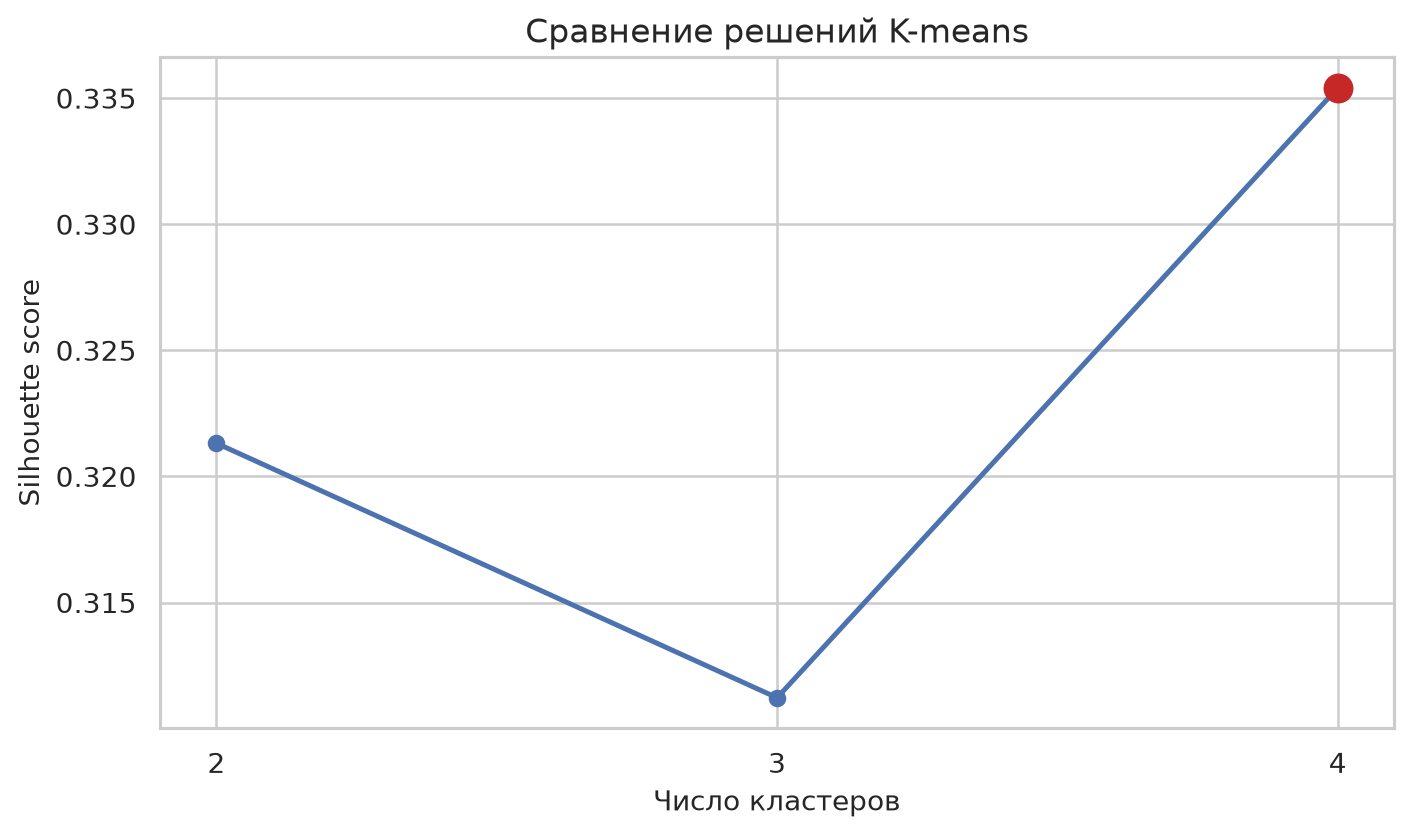

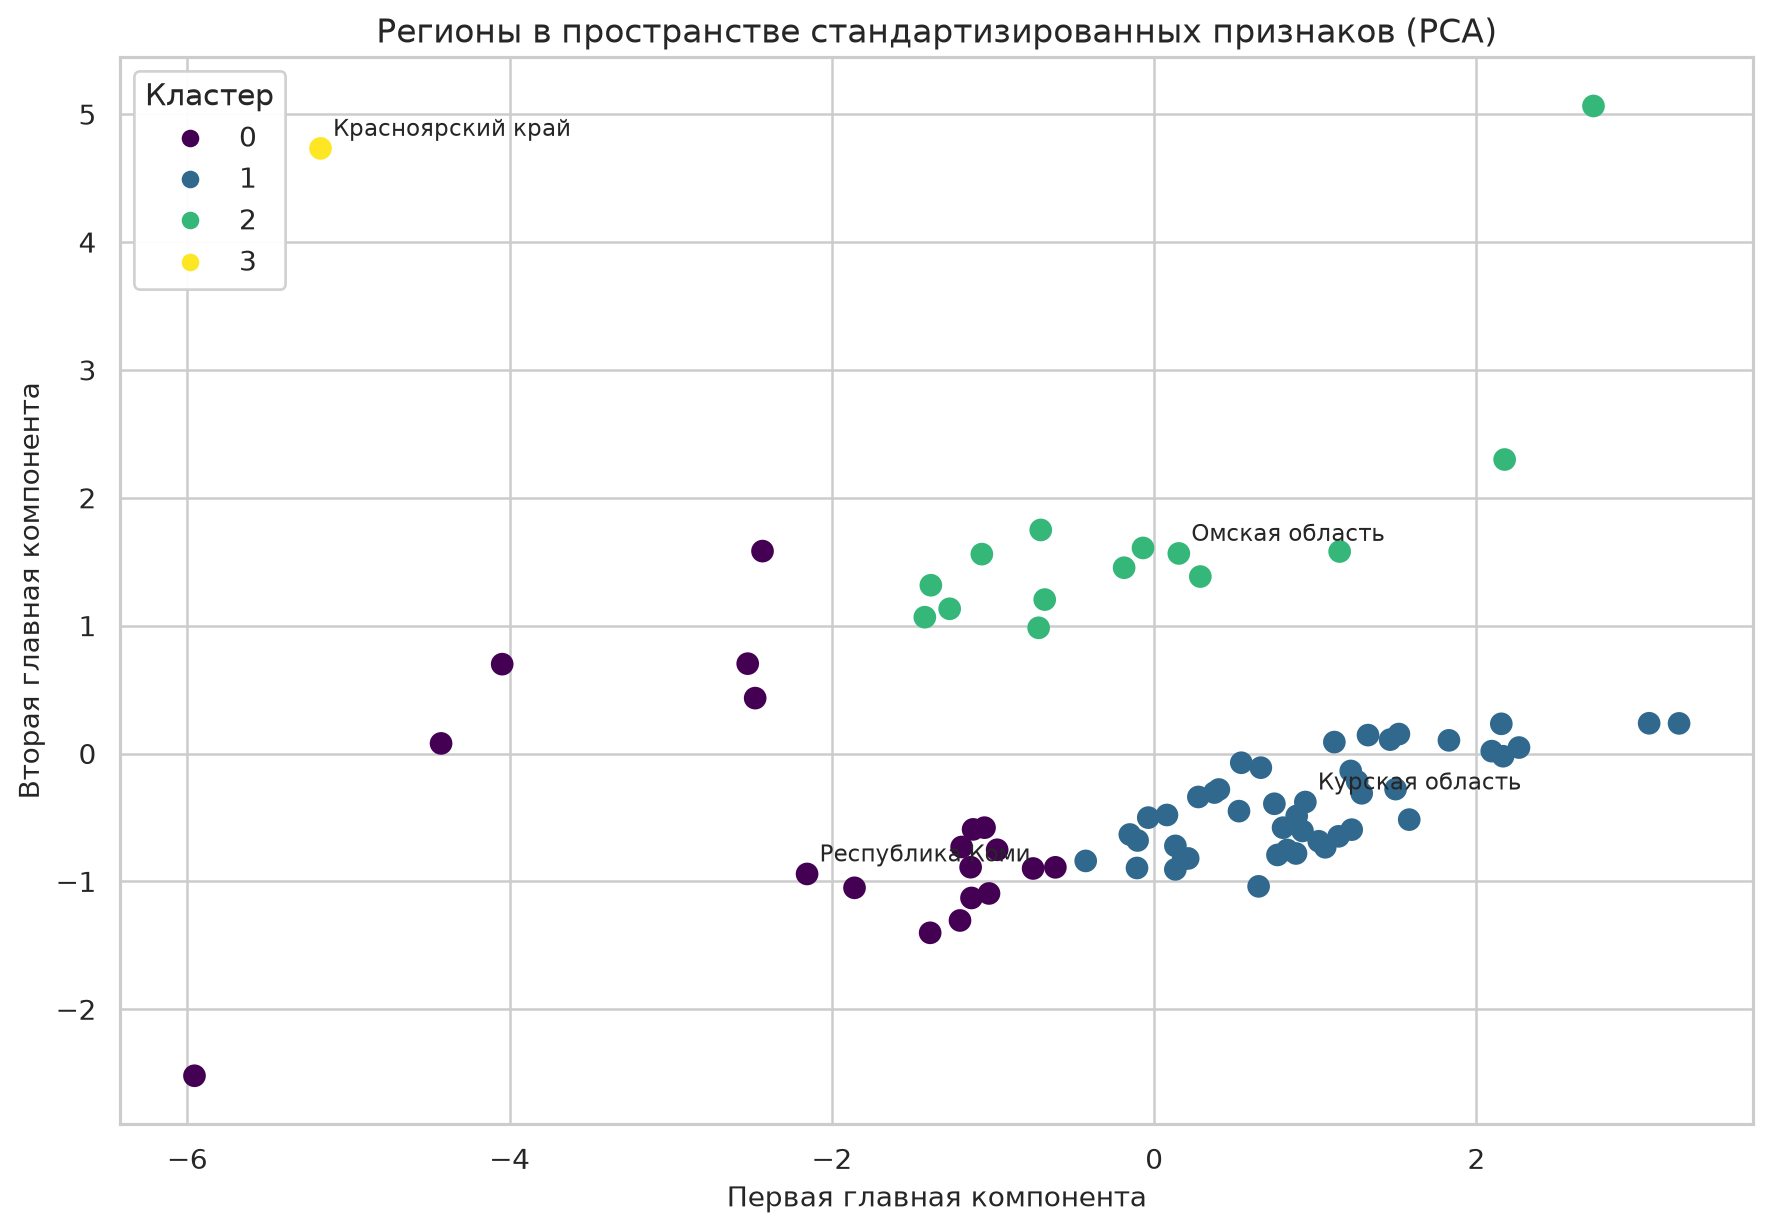

In [5]:
profile_columns = ["mean_value", "coefficient_of_variation", "cagr", "total_growth", "max_annual_decline", "negative_years_share", "n_regions"]
display(profiles[profile_columns].round(4))
for cluster, row in profiles.iterrows():
    print(f"\nКластер {cluster} ({int(row['n_regions'])} регионов):\n{row['regions']}")
tsp.create_cluster_plots(clustered, evaluation, scaled)
display(Image(filename=str(tsp.FIGURES_DIR / "01_silhouette.png")))
display(Image(filename=str(tsp.FIGURES_DIR / "02_clusters_pca.png")))

## Этап 3. Выбор регионов для детального прогнозирования

Внутри каждого кластера сначала найден регион с минимальным евклидовым расстоянием до центроида в стандартизированном пространстве. Поскольку кластеров четыре, для прогноза выбраны три представителя из разных кластеров с максимальной суммой попарных расстояний: так сохраняется наибольшее разнообразие динамических паттернов.

In [6]:
selected_names, selected_stats = tsp.select_representatives(clustered, complete)
print("Выбранные регионы:", ", ".join(selected_names))
display(selected_stats.round(3))

Выбранные регионы: Республика Коми, Курская область, Красноярский край


,region_name,cluster,distance_to_centroid,mean_value,min_value,min_year,max_value,max_year,linear_slope_rub_per_year,relative_slope_percent
0,Республика Коми,0,0.824,254857.196,27557.3,2000,594601.8,2023,22569.874,8.856
1,Курская область,1,0.147,190928.508,15690.0,2000,478025.8,2023,19575.576,10.253
2,Красноярский край,3,0.000,232202.529,28411.2,2000,556338.0,2023,20211.434,8.704


- **Республика Коми** — представитель кластера 0 с относительно высоким средним уровнем и умеренным темпом роста.
- **Курская область** — наиболее близка к центру кластера 1; характеризуется высоким среднегодовым приростом и отсутствием годовых снижений в ряду.
- **Красноярский край** — единственный представитель кластера 3, выбран как крайний, но содержательно важный случай структурного скачка источника.

Наклон линейного тренда показывает среднее изменение в рублях в год, а относительный наклон позволяет сравнивать регионы с разным масштабом.

## Этап 4. Анализ выбранных временных рядов

Тренд выделяется HP-фильтром с λ = 6,25, что соответствует распространённой настройке для годовых данных. Тест Дики — Фуллера проводится для уровня и первой разности. Нулевая гипотеза — наличие единичного корня; при p-value < 0,05 она отклоняется.

ACF и PACF строятся для первых разностей: медленно затухающая автокорреляция исходных трендовых уровней малоинформативна для выбора p и q. Внутригодовая сезонность в годовых данных отсутствует, поэтому сезонная декомпозиция не применяется.

,region_name,transformation,adf_statistic,p_value,used_lag,n_obs,critical_1_percent,critical_5_percent,stationary_at_5_percent
0,Республика Коми,level,3.8050,1.0000,0,23,-3.7529,-2.9985,False
1,Республика Коми,first_difference,1.1648,0.9957,4,18,-3.8591,-3.0420,False
2,Курская область,level,4.6274,1.0000,0,23,-3.7529,-2.9985,False
3,Курская область,first_difference,-0.7750,0.8264,9,13,-4.0689,-3.1271,False
4,Красноярский край,level,0.8696,0.9927,0,23,-3.7529,-2.9985,False
5,Красноярский край,first_difference,1.7253,0.9982,9,13,-4.0689,-3.1271,False


,region_name,cycle_std_rub,largest_positive_cycle_year,largest_positive_cycle_rub,largest_negative_cycle_year,largest_negative_cycle_rub
0,Республика Коми,7141.35,2023,13192.80,2010,-15048.49
1,Курская область,5655.59,2022,9257.48,2020,-21254.92
2,Красноярский край,19618.16,2004,74052.30,2005,-26708.26


,region_name,significant_acf_lags,significant_pacf_lags,initial_p_hypothesis,initial_q_hypothesis,note
0,Республика Коми,нет,нет,0,0,Гипотеза по первым разностям; окончательный порядок выбирается по AIC на train
1,Курская область,нет,нет,0,0,Гипотеза по первым разностям; окончательный порядок выбирается по AIC на train
2,Красноярский край,нет,нет,0,0,Гипотеза по первым разностям; окончательный порядок выбирается по AIC на train



Республика Коми


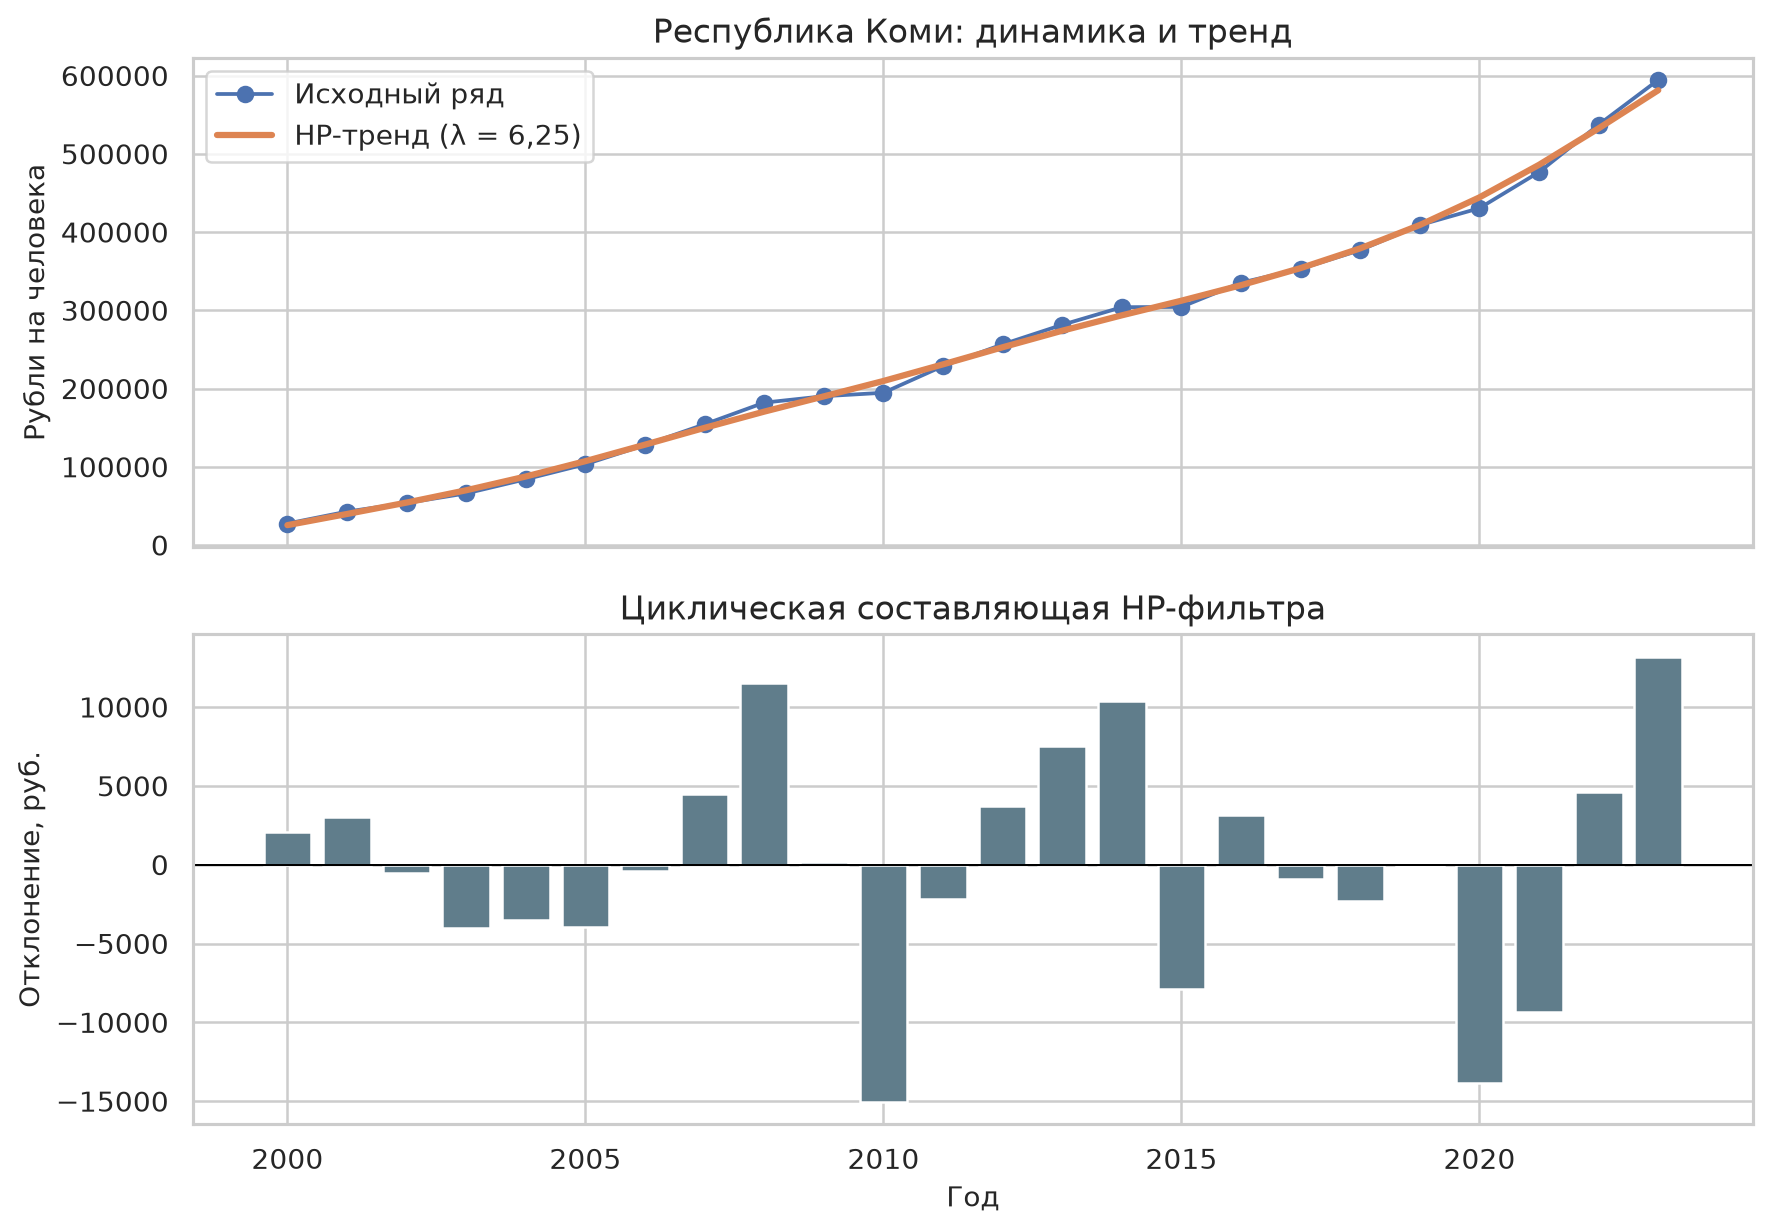

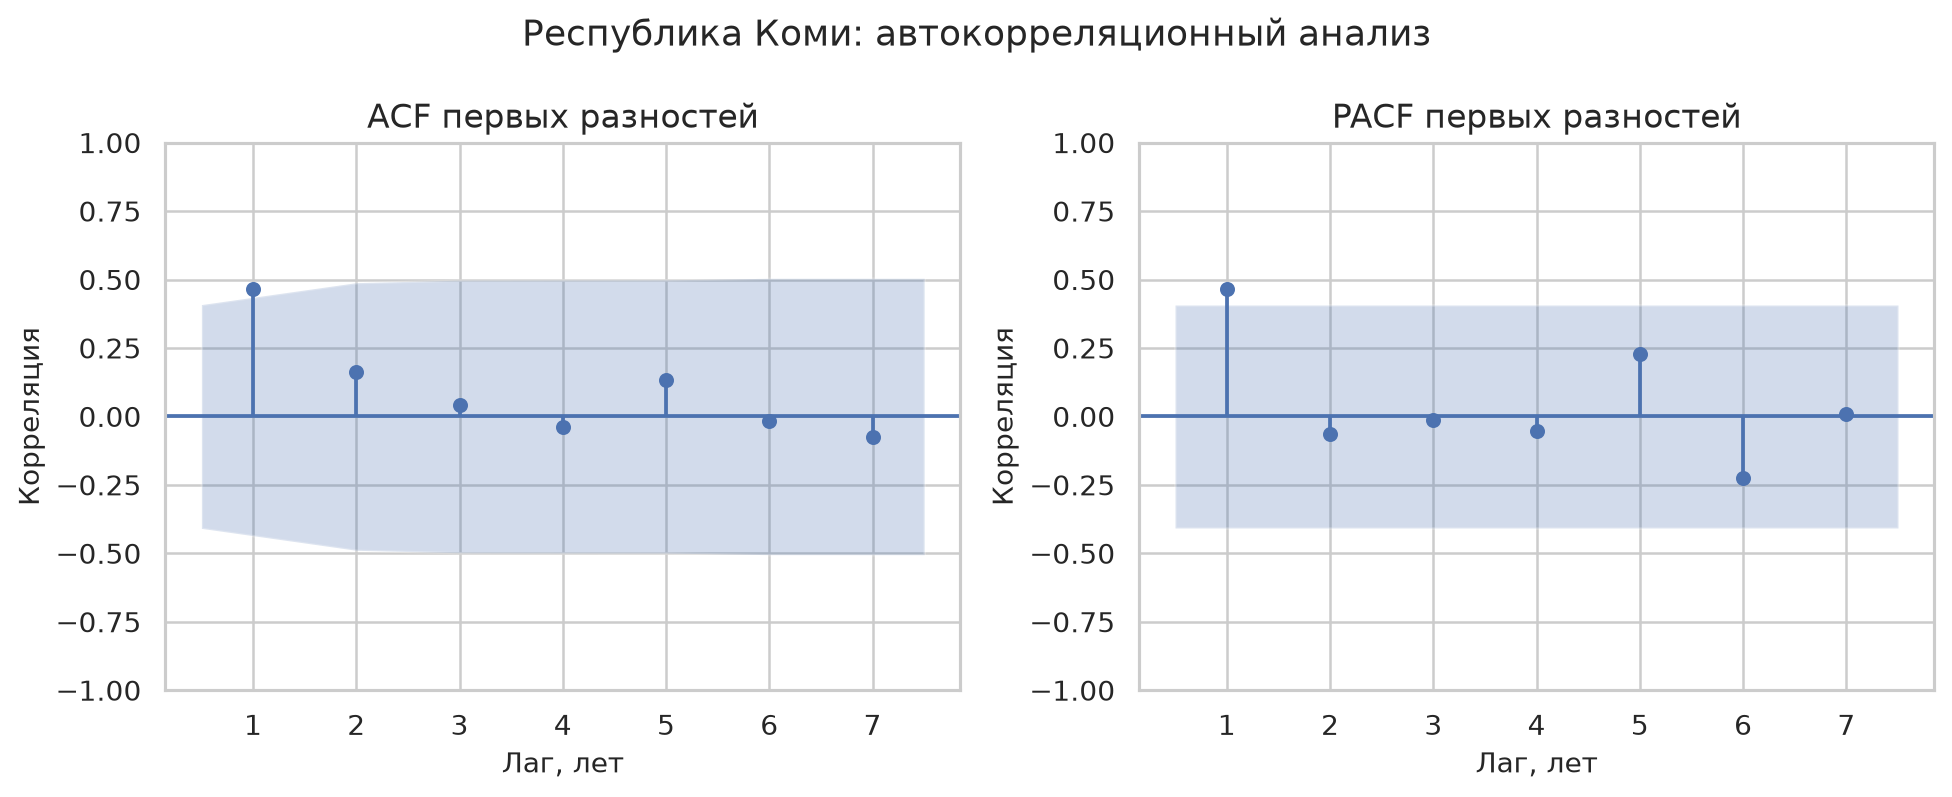


Курская область


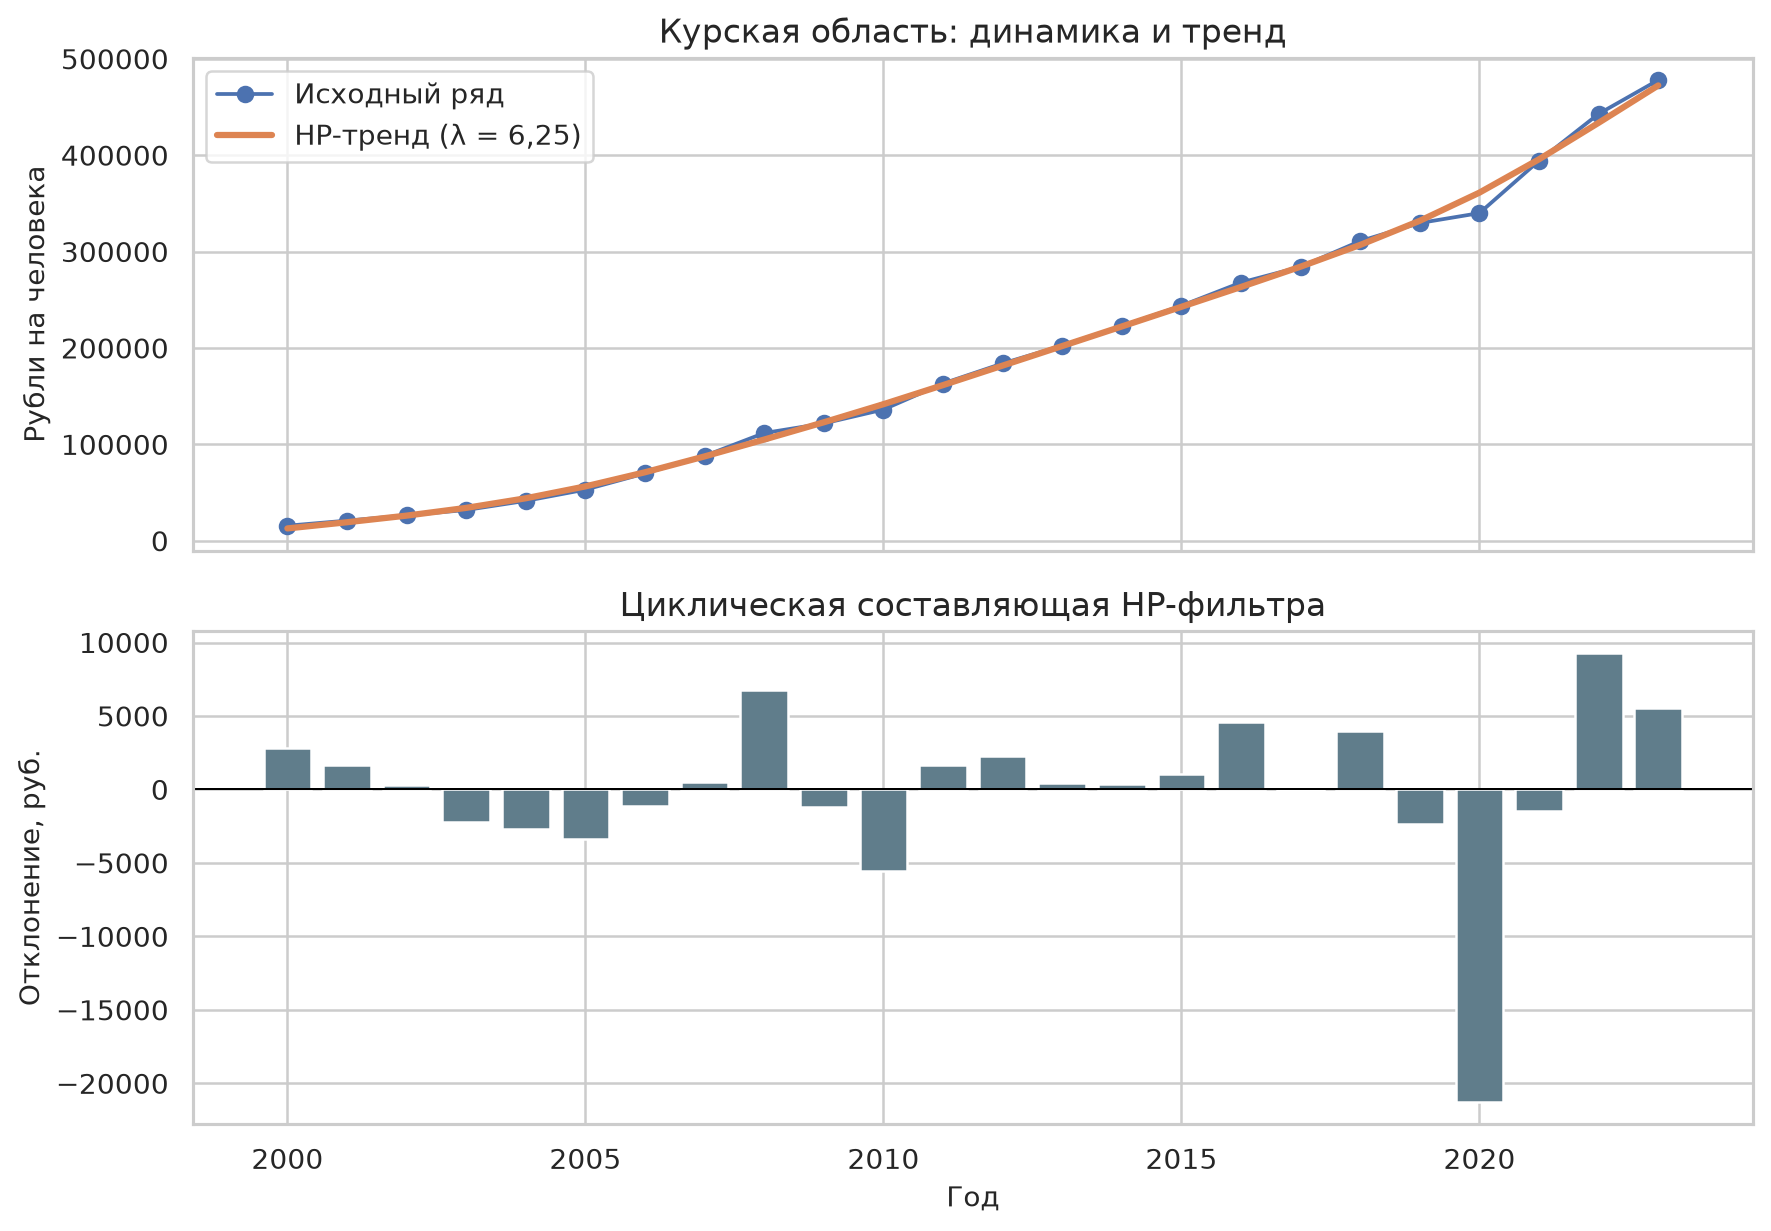

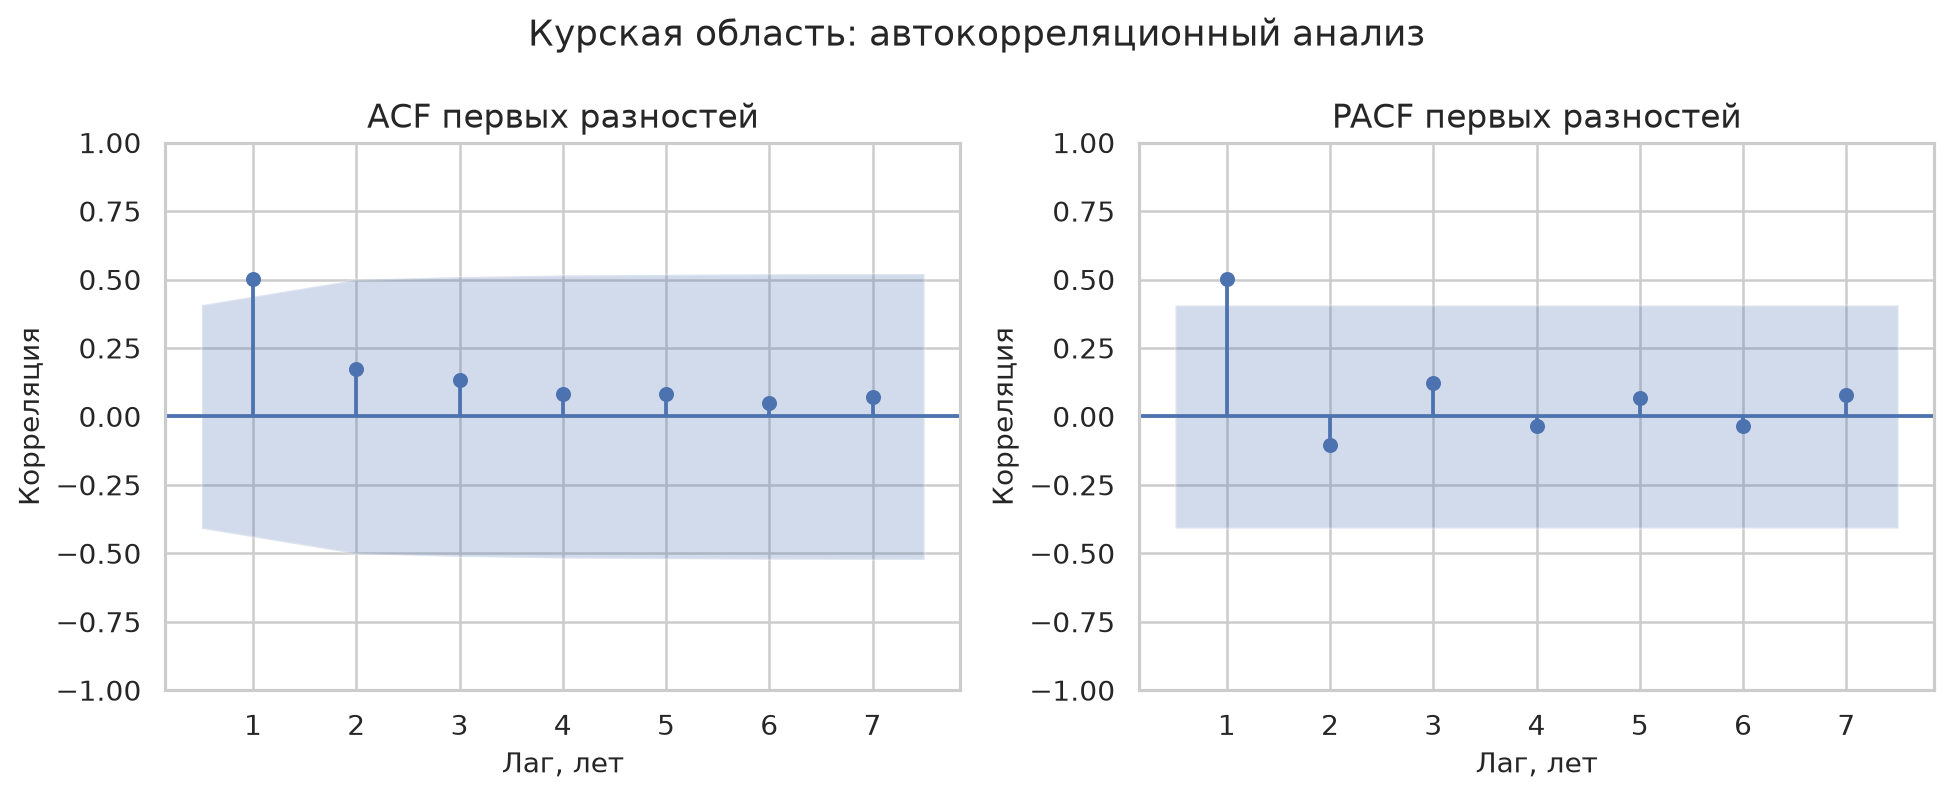


Красноярский край


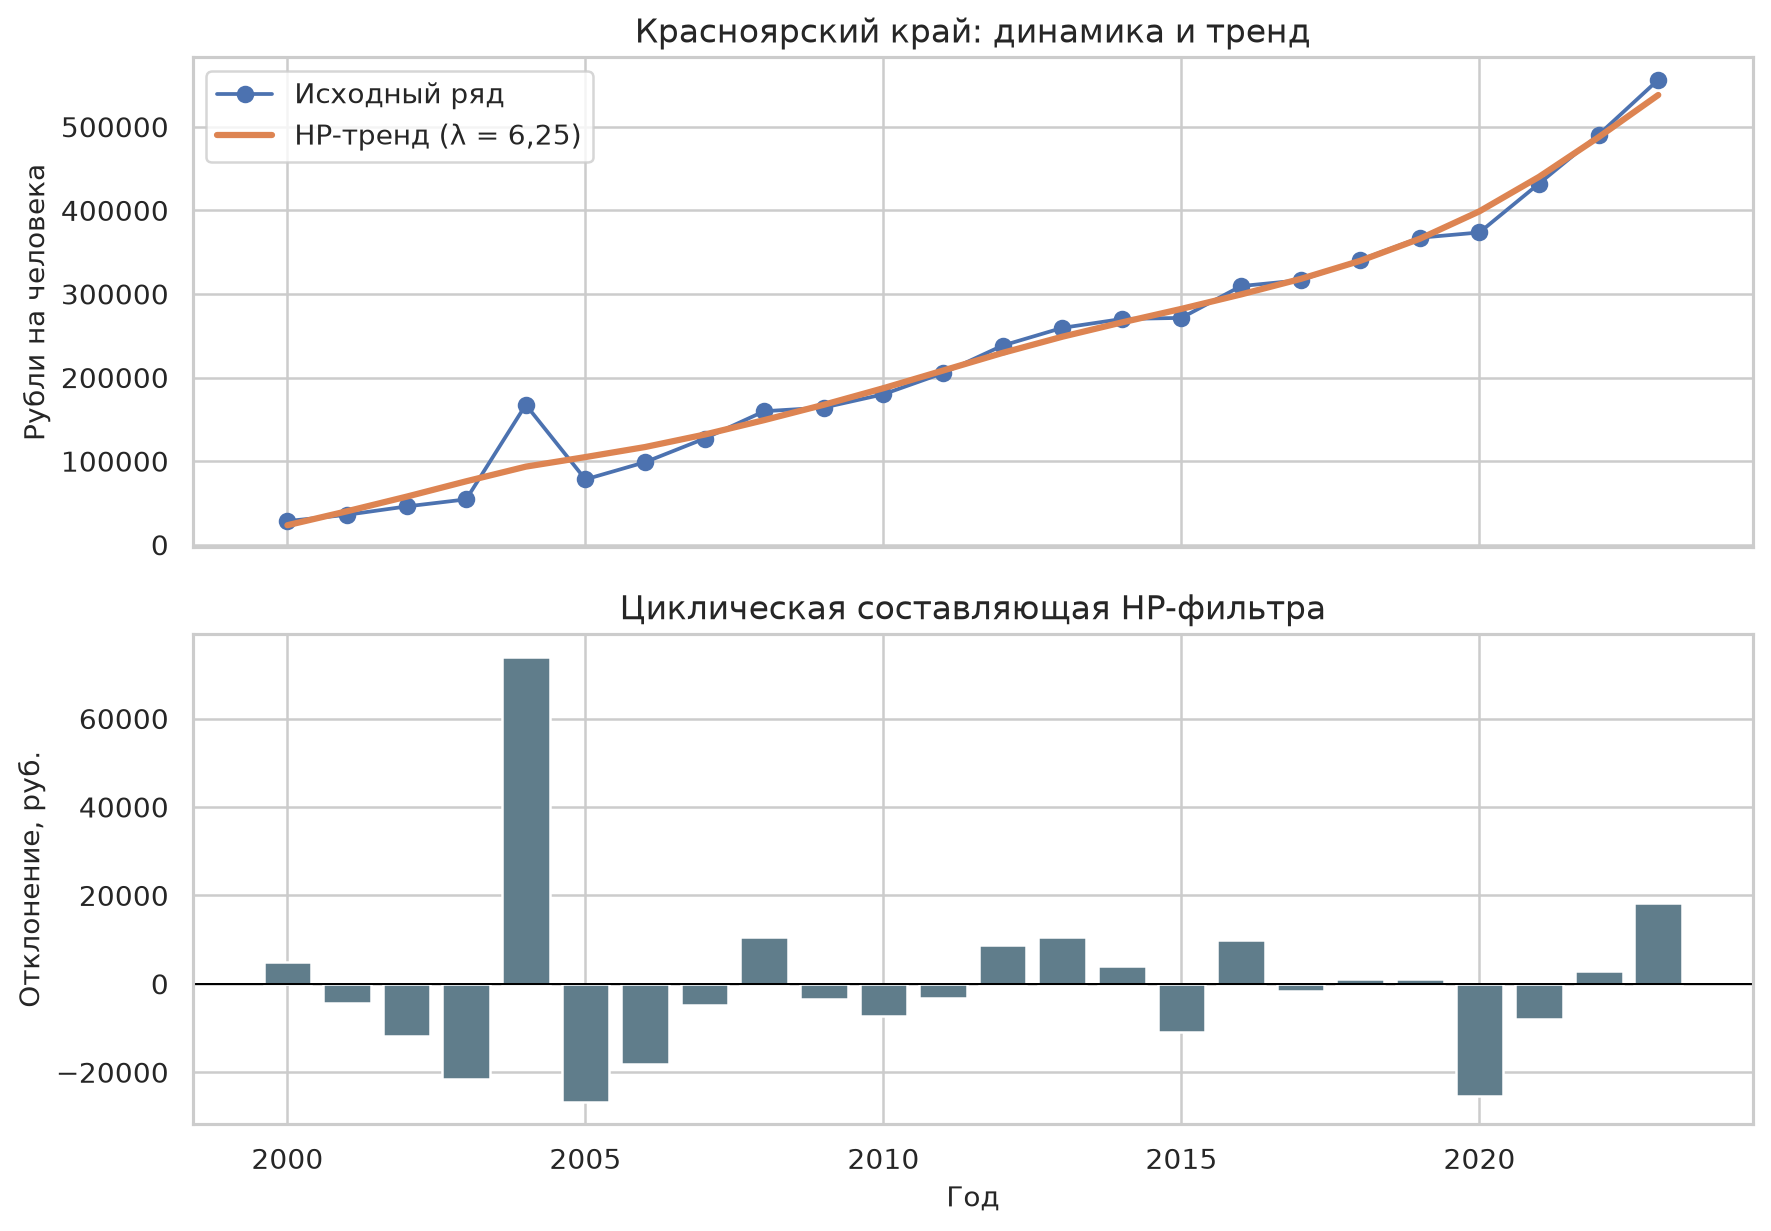

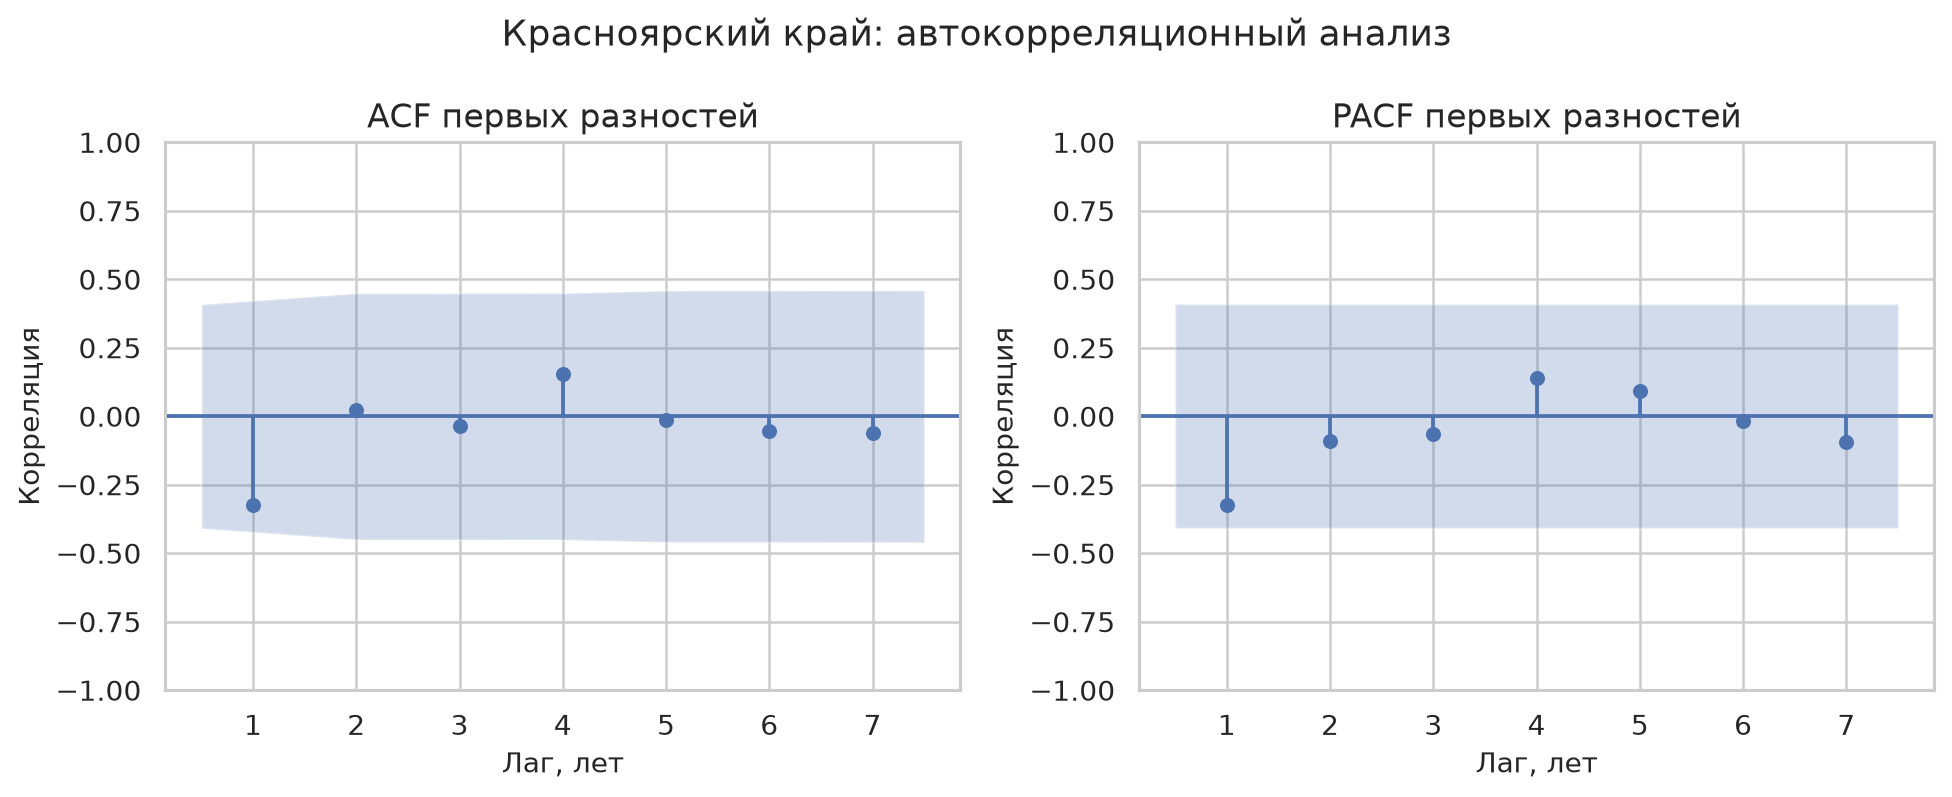

In [7]:
adf_results, cycles, hypotheses = tsp.analyze_selected_series(selected_names, complete)
display(adf_results.round(4))
display(cycles.round(2))
display(hypotheses)
for number, region in enumerate(selected_names, start=1):
    print(f"\n{region}")
    display(Image(filename=str(tsp.FIGURES_DIR / f"03_region_{number}_trend.png")))
    display(Image(filename=str(tsp.FIGURES_DIR / f"04_region_{number}_acf_pacf.png")))

Для всех трёх уровней ADF не отклоняет нестационарность: p-value составляет 1,0000 для Коми и Курской области и 0,9927 для Красноярского края. Первые разности также не проходят тест на уровне 5% (p-value 0,9957; 0,8264; 0,9982 соответственно). Это связано с меняющимся темпом номинального роста, структурными шоками и малой длиной ряда; мощность ADF на 24 наблюдениях ограничена.

На графиках ACF/PACF первых разностей нет значимых лагов на уровне 5%, поэтому исходная гипотеза для всех регионов — p = q = 0. Она не навязывается итоговой модели: далее порядок независимо подбирается по AIC на обучающей выборке. Наиболее высокий абсолютный наклон у Коми (22 570 руб./год), наиболее высокий относительный — у Курской области (10,25% среднего уровня в год). По стандартному отклонению HP-цикла наиболее волатилен Красноярский край.

## Этап 5. Прогнозирование

Последние пять лет (2019–2023) выделены в тест, обучение занимает 2000–2018 годы — 19 из 24 наблюдений (79,2%). Сравниваются:

1. `NaiveForecaster(strategy="last")` из sktime;
2. линейная модель Холта;
3. ARIMA с p, d, q ∈ {0, 1, 2}, d ∈ {0, 1}, выбранным по AIC только на train.

Лучшая модель определяется по RMSE, MAPE используется как сопоставимая относительная метрика. Затем выполняется rolling forecast: окно длиной 19 лет сдвигается на один год, модель переобучается, делается одношаговый прогноз. Финальный прогноз строится на всех данных до 2026 года.

,region_name,model,model_label,rmse,mape_percent,train_start,train_end,test_start,test_end,arima_order
0,Республика Коми,naive,Наивный,131840.283,21.529,2000,2018,2019,2023,—
1,Республика Коми,holt,Holt,73227.992,11.432,2000,2018,2019,2023,—
2,Республика Коми,arima,ARIMA,57512.060,8.166,2000,2018,2019,2023,"(2, 1, 2)"
3,Курская область,naive,Наивный,103408.395,20.020,2000,2018,2019,2023,—
4,Курская область,holt,Holt,31396.892,6.015,2000,2018,2019,2023,—
5,Курская область,arima,ARIMA,23049.131,4.761,2000,2018,2019,2023,"(2, 1, 2)"
6,Красноярский край,naive,Наивный,125730.893,21.292,2000,2018,2019,2023,—
7,Красноярский край,holt,Holt,80355.901,13.008,2000,2018,2019,2023,—
8,Красноярский край,arima,ARIMA,49037.221,7.286,2000,2018,2019,2023,"(1, 1, 2)"


Сводка скользящей проверки лучших моделей:


,region_name,model,model_label,fixed_rmse,fixed_mape_percent,rolling_rmse,rolling_mape_percent
0,Республика Коми,arima,ARIMA,57512.060,8.166,38200.341,5.084
1,Курская область,arima,ARIMA,23049.131,4.761,16416.215,3.116
2,Красноярский край,arima,ARIMA,49037.221,7.286,32214.245,5.374


Прогноз лучших моделей на 2024–2026 годы:


,region_name,model,model_label,year,forecast,growth_from_2023_percent,final_arima_order
0,Республика Коми,arima,ARIMA,2024,642480.54,8.05,"(1, 1, 2)"
1,Республика Коми,arima,ARIMA,2025,689405.68,15.94,"(1, 1, 2)"
2,Республика Коми,arima,ARIMA,2026,738675.66,24.23,"(1, 1, 2)"
3,Курская область,arima,ARIMA,2024,522500.56,9.30,"(2, 1, 2)"
4,Курская область,arima,ARIMA,2025,570258.24,19.29,"(2, 1, 2)"
5,Курская область,arima,ARIMA,2026,622461.59,30.22,"(2, 1, 2)"
6,Красноярский край,arima,ARIMA,2024,571798.10,2.78,"(1, 1, 2)"
7,Красноярский край,arima,ARIMA,2025,618914.09,11.25,"(1, 1, 2)"
8,Красноярский край,arima,ARIMA,2026,668442.95,20.15,"(1, 1, 2)"



Республика Коми


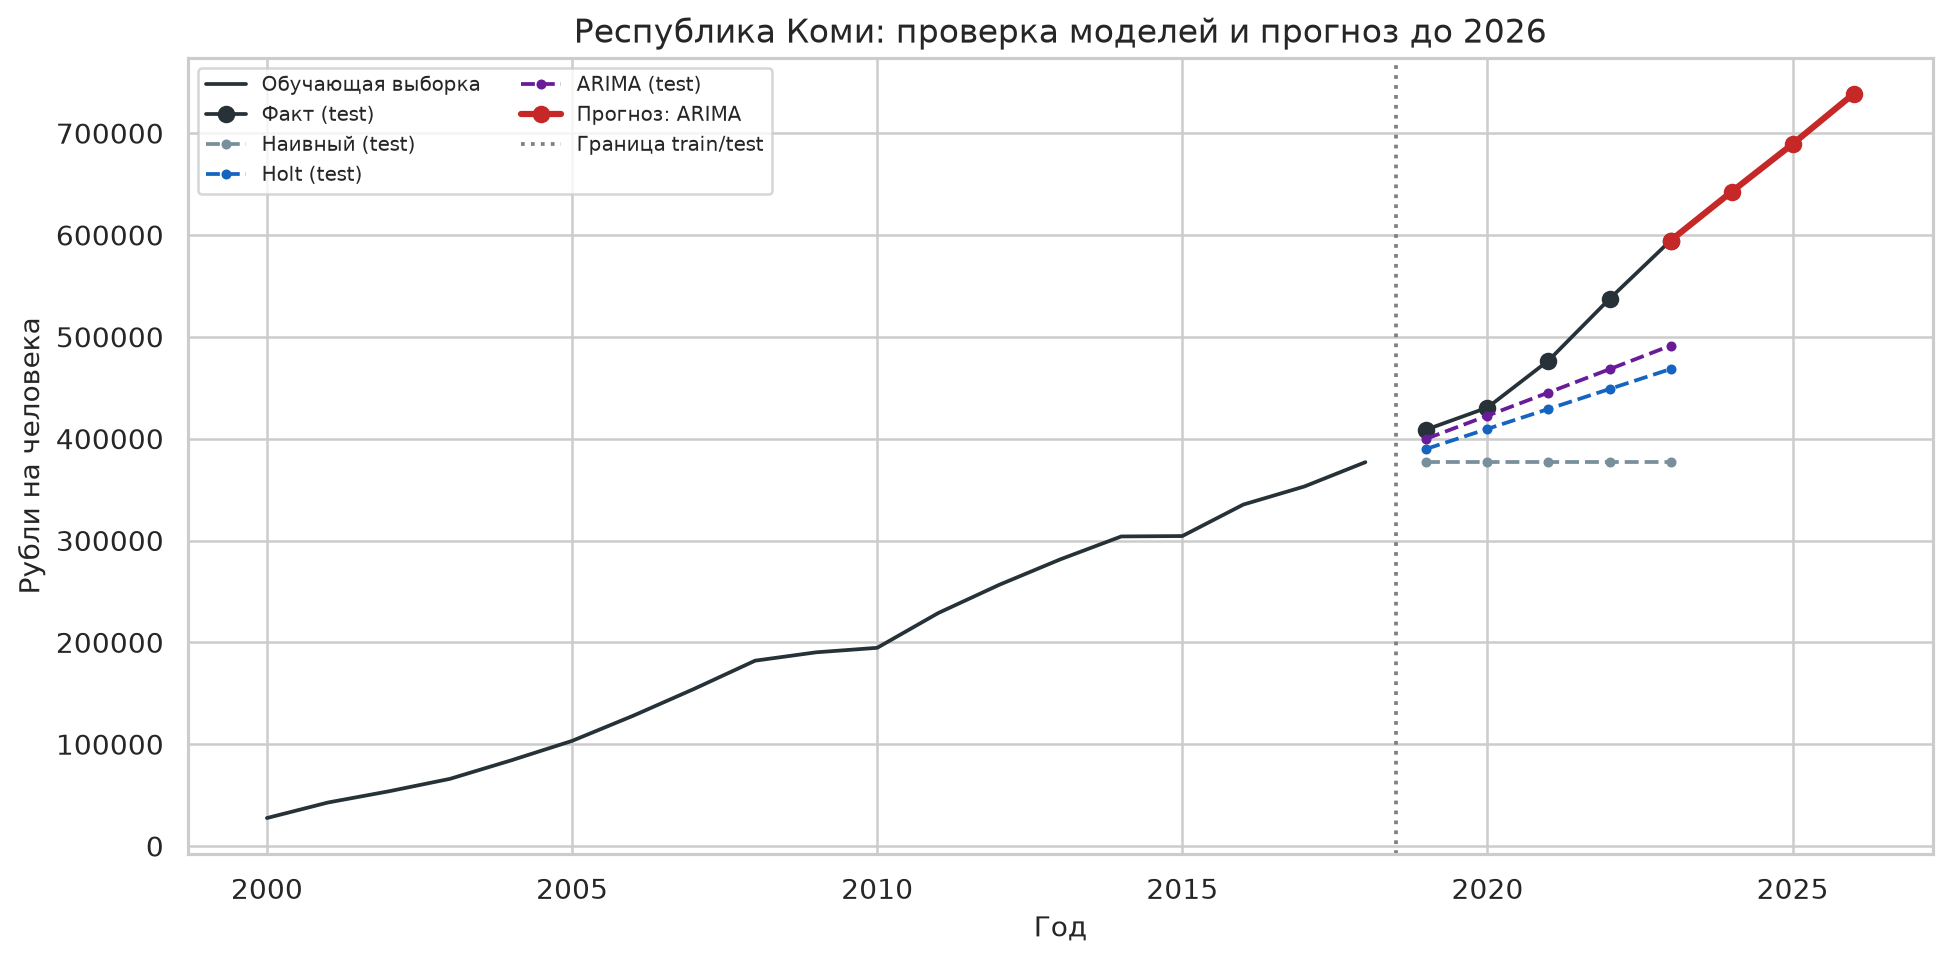


Курская область


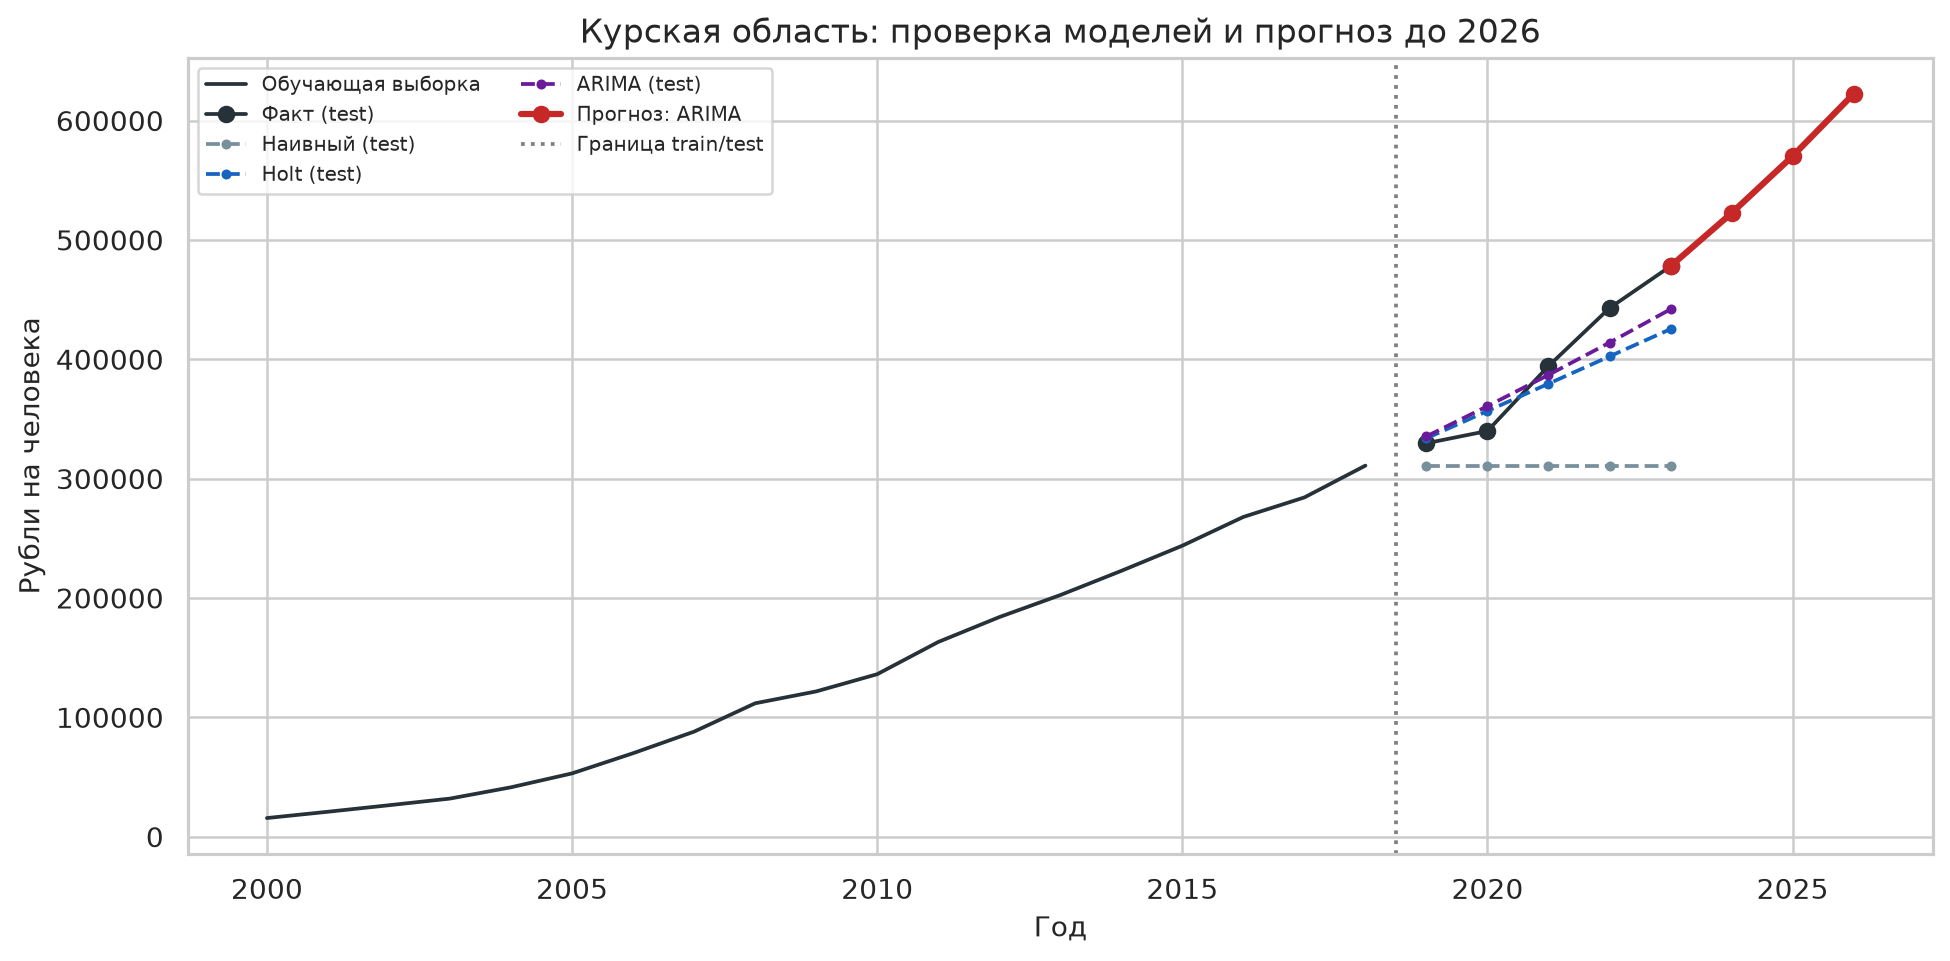


Красноярский край


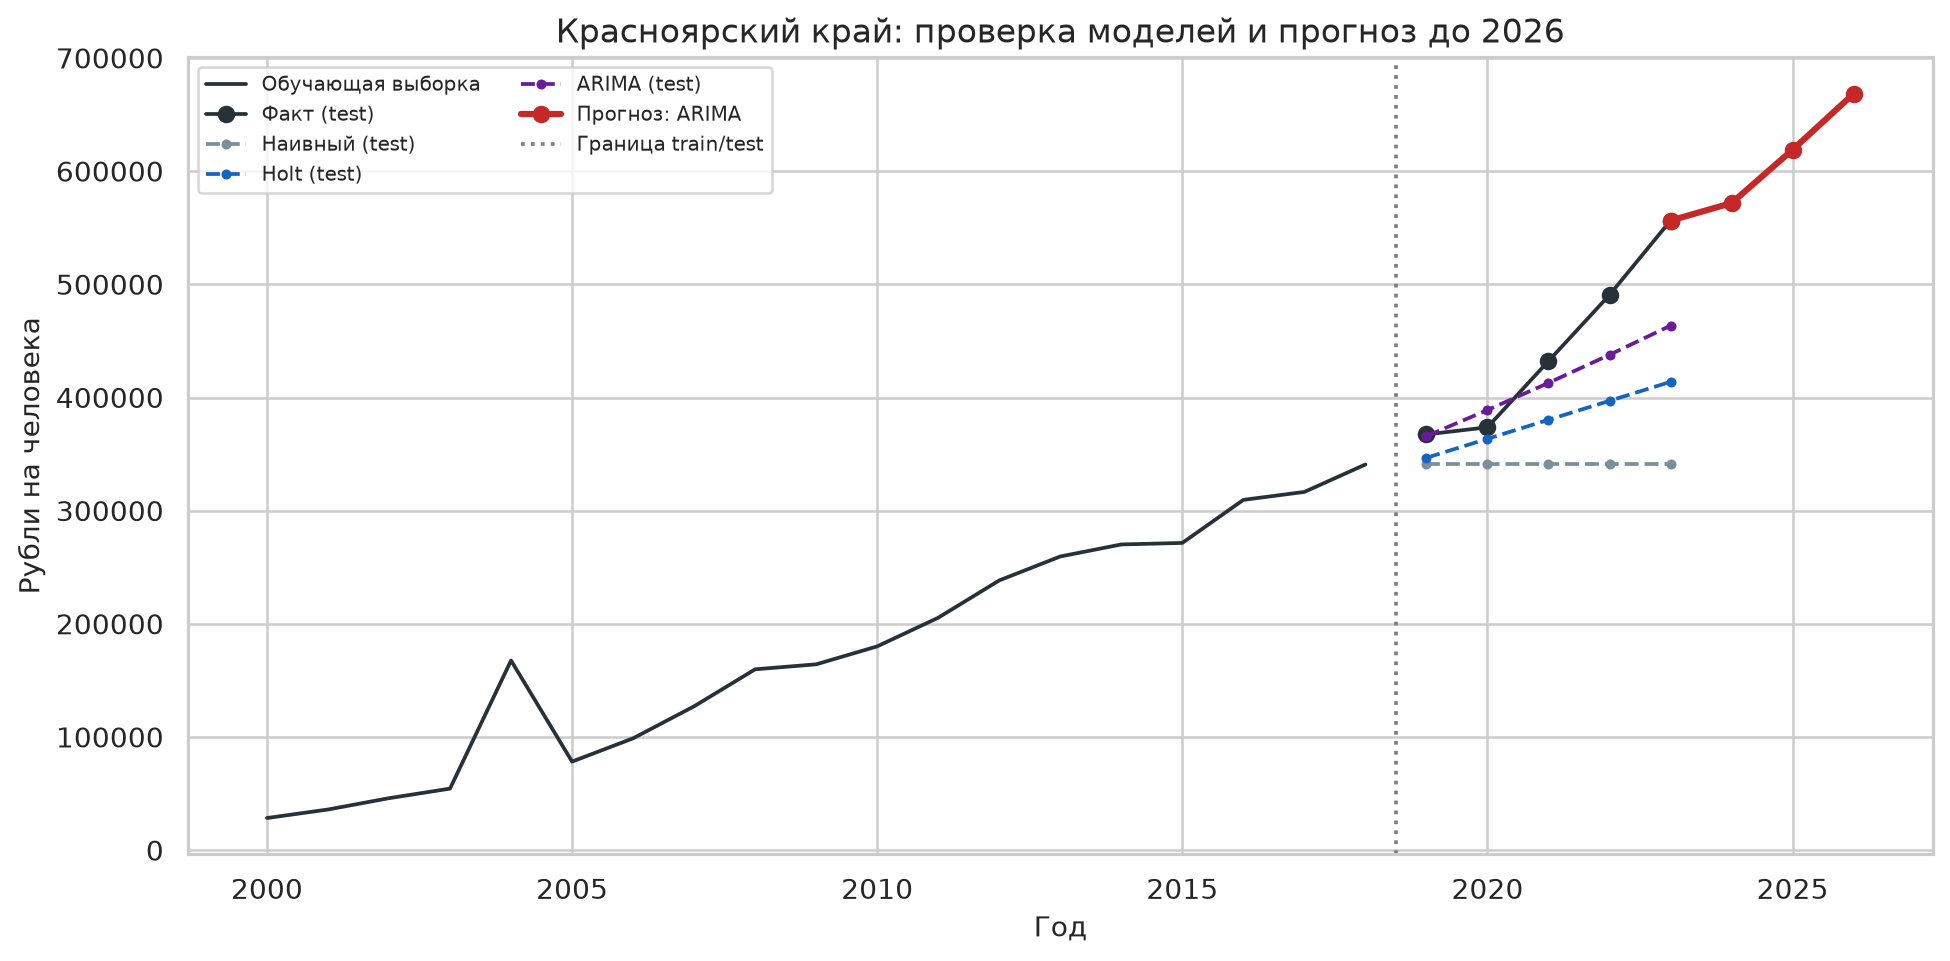

In [8]:
forecasts = tsp.forecast_selected_regions(selected_names, complete)
metrics = forecasts["metrics"]
future_forecasts = forecasts["future_forecasts"]
rolling_metrics = forecasts["rolling_metrics"]
rolling_predictions = forecasts["rolling_predictions"]
top_errors = forecasts["top_errors"]

display(metrics.round(3))
print("Сводка скользящей проверки лучших моделей:")
display(rolling_metrics.round(3))
print("Прогноз лучших моделей на 2024–2026 годы:")
display(future_forecasts.round(2))
for number, region in enumerate(selected_names, start=1):
    print(f"\n{region}")
    display(Image(filename=str(tsp.FIGURES_DIR / f"05_region_{number}_forecast.png")))

ARIMA показала минимальный RMSE для каждого региона: **57 512 руб.** для Коми, **23 049 руб.** для Курской области и **49 037 руб.** для Красноярского края. Наивный бейзлайн существенно хуже из-за выраженного номинального тренда. Скользящая одношаговая проверка даёт меньшие ошибки, чем фиксированный пятилетний прогноз: регулярное обновление модели и сокращение горизонта улучшают точность. Это не доказывает точность трёхлетнего прогноза, но подтверждает устойчивость преимущества ARIMA на доступном тесте.

## Этап 6. Анализ ошибок

In [9]:
error_columns = ["region_name", "error_rank", "year", "actual", "predicted", "absolute_error", "absolute_percentage_error", "event_hypothesis"]
for region in selected_names:
    print(f"\n{region}: пять ошибок скользящего прогноза")
    display(top_errors.loc[top_errors["region_name"] == region, error_columns].round(2))


Республика Коми: пять ошибок скользящего прогноза


,region_name,error_rank,year,actual,predicted,absolute_error,absolute_percentage_error,event_hypothesis
0,Республика Коми,1,2023,594601.8,670181.20,75579.40,12.71,Адаптация экономики и номинальный ценовой рост могли сохранить отклонение от тренда
1,Республика Коми,2,2022,537332.8,503665.36,33667.44,6.27,"Санкционный шок, перестройка рынков и инфляция могли изменить динамику"
2,Республика Коми,3,2021,476753.1,457559.28,19193.82,4.03,Восстановление после шока 2020 года и изменение номинальных цен могли усилить рост
3,Республика Коми,4,2019,409038.8,400018.70,9020.10,2.21,До пандемийного шока; по одному ряду причину отклонения идентифицировать нельзя
4,Республика Коми,5,2020,430627.3,431534.98,907.68,0.21,Пандемия COVID-19 и ограничения могли нарушить прежнюю траекторию потребления



Курская область: пять ошибок скользящего прогноза


,region_name,error_rank,year,actual,predicted,absolute_error,absolute_percentage_error,event_hypothesis
5,Курская область,1,2021,394356.6,361054.58,33302.02,8.44,Восстановление после шока 2020 года и изменение номинальных цен могли усилить рост
6,Курская область,2,2020,339993.3,353592.14,13598.84,4.00,Пандемия COVID-19 и ограничения могли нарушить прежнюю траекторию потребления
7,Курская область,3,2019,329726.9,335469.09,5742.19,1.74,До пандемийного шока; по одному ряду причину отклонения идентифицировать нельзя
8,Курская область,4,2022,442957.9,439549.00,3408.90,0.77,"Санкционный шок, перестройка рынков и инфляция могли изменить динамику"
9,Курская область,5,2023,478025.8,475040.15,2985.65,0.62,Адаптация экономики и номинальный ценовой рост могли сохранить отклонение от тренда



Красноярский край: пять ошибок скользящего прогноза


,region_name,error_rank,year,actual,predicted,absolute_error,absolute_percentage_error,event_hypothesis
10,Красноярский край,1,2022,490620.9,441752.03,48868.87,9.96,"Санкционный шок, перестройка рынков и инфляция могли изменить динамику"
11,Красноярский край,2,2021,432207.1,389622.41,42584.69,9.85,Восстановление после шока 2020 года и изменение номинальных цен могли усилить рост
12,Красноярский край,3,2023,556338.0,525200.99,31137.01,5.60,Адаптация экономики и номинальный ценовой рост могли сохранить отклонение от тренда
13,Красноярский край,4,2020,373693.6,369773.96,3919.64,1.05,Пандемия COVID-19 и ограничения могли нарушить прежнюю траекторию потребления
14,Красноярский край,5,2019,367377.7,365864.94,1512.76,0.41,До пандемийного шока; по одному ряду причину отклонения идентифицировать нельзя


Наибольшие ошибки концентрируются в 2021–2023 годах. Для Коми максимальная ошибка — 75 579 руб. в 2023 году (12,71%), для Курской области — 33 302 руб. в 2021 году (8,44%), для Красноярского края — 48 869 руб. в 2022 году (9,96%). Возможные объяснения — постпандемийное восстановление, санкционный шок, инфляция и адаптация рынков. Это **гипотезы по совпадению во времени**, а не доказанные причинно-следственные связи: в наборе нет дополнительных объясняющих переменных.

## Этап 7. Индивидуальные рекомендации

### Республика Коми
1. При планировании номинальных расходов на поддержку потребления использовать базовый ориентир **738 676 руб. на человека к 2026 году**, что на **24,23%** выше фактического значения 2023 года.
2. Ежегодно обновлять прогноз: скользящая ошибка RMSE равна **38 200 руб.**, а наибольшее отклонение произошло в 2023 году. Для осторожного сценария на 2026 год можно заложить диапазон примерно **700 475–776 876 руб.** (прогноз ± один rolling RMSE), не трактуя его как статистический доверительный интервал.
3. Поскольку траектория предполагает замедление роста после 2024 года, сравнивать исполнение программ не только с итоговым ориентиром, но и с промежуточными значениями **642 481 руб. в 2024-м** и **689 406 руб. в 2025-м**.

### Курская область
1. Для номинального планирования на 2026 год использовать ориентир **622 462 руб.**, что на **30,22%** выше уровня 2023 года; промежуточные контрольные значения — **522 501** и **570 258 руб.**.
2. Сохранять ежегодную переоценку тренда: rolling RMSE составляет **16 416 руб.**, а самая крупная ошибка связана с восстановительным ростом 2021 года. Осторожный диапазон на 2026 год — примерно **606 045–638 878 руб.**.
3. При сравнении с другими регионами учитывать, что Курская область имеет самый высокий относительный наклон среди выбранных (10,25% среднего уровня в год), поэтому одинаковый абсолютный прирост означает для неё иную динамику, чем для Коми.

### Красноярский край
1. Базовый прогноз на 2026 год — **668 443 руб. на человека**, или **+20,15%** к 2023 году; контрольные значения на 2024 и 2025 годы — **571 798** и **618 914 руб.**.
2. До использования долгосрочных прогнозов проверить скачок 2004 года и снижение 2005-го по первоисточнику: именно эти наблюдения выделили регион в отдельный кластер. Если это методологический разрыв, требуется сопоставимый ряд или дамми-переменная.
3. Для сценарного резерва использовать rolling RMSE **32 214 руб.**; тогда ориентировочный рабочий диапазон на 2026 год — **636 229–700 657 руб.**. Наибольшие свежие ошибки 2021–2022 годов показывают необходимость ежегодной корректировки.

Все рекомендации относятся к **номинальным** суммам. Для решений о реальном уровне жизни их необходимо дополнить региональными индексами цен.

## Этап 8. Общие выводы и ограничения

В данных выделены четыре группы: 19 регионов кластера 0, 45 — кластера 1, 14 — кластера 2 и отдельная аномальная траектория Красноярского края. Группы различаются не только уровнем, но и темпом роста и наличием годовых снижений. Для трёх выбранных типов динамики ARIMA превзошла Holt и наивный прогноз по RMSE и MAPE на фиксированном тесте; скользящая переоценка снизила ошибки.

**Ограничения:** всего 24 годовых наблюдения; показатель не дефлирован; модели не содержат доходы, цены, занятость, демографию и санкционные переменные; ARIMA описывает прошлую зависимость, но не предсказывает новые структурные шоки; однорегиональный кластер чувствителен к аномалии источника; rolling RMSE меньше частично из-за одношагового горизонта и не должен напрямую приравниваться к ошибке трёхлетнего прогноза.

**Улучшения:** добавить региональные дефляторы и реальные доходы, проверить методологические разрывы Росстата, использовать интервенционные модели для кризисных лет, расширить историю и применить блоковую перекрёстную проверку с несколькими горизонтами. Для практического использования нужны интервальные прогнозы и ежегодная переоценка.

## Сохранение результатов

In [10]:
tsp.save_outputs(
    raw, subjects, complete, long, excluded, features, clustered, evaluation,
    profiles, selected_stats, adf_results, cycles, hypotheses, forecasts,
)
print("Таблицы сохранены: outputs/tables")
print("Графики сохранены: outputs/figures")
print("Сводка сохранена: outputs/summary.json")

Таблицы сохранены: outputs/tables
Графики сохранены: outputs/figures
Сводка сохранена: outputs/summary.json
